# Week 5 - Part C: the two-map activity, on real readers

Q1 builds both maps from `county_crime.csv`: same boundaries, same five-class scheme, same ramp, only the denominator differs. Q2 is an experiment on **real readers**. The harness is below, and the scoring cell reads whatever is in `submission/partC_reader_results.csv`. Nothing in that file is typed in by hand here, and no reader has been made up.

All data is synthetic course data for CDB601220 (Week 5).

In [1]:
import sys
import argparse
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon as MplPolygon

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import geolib as gl
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
for p in (CHARTS, SUB):
    p.mkdir(exist_ok=True)
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
RESULTS = SUB / "partC_reader_results.csv"
COLUMNS = ["reader", "a1", "a2", "a3", "b1", "b2", "b3", "overlap", "how", "recorded_at"]

FEATS = gl.read_geojson(DATA / "districts.geojson")
LAT_TS = gl._collection_lat_ts(FEATS)
FEATS20 = [f for f in FEATS if f["code"] <= "D20"]
LAT20 = gl._collection_lat_ts(FEATS20)          # choropleth() projects the 20 drawn polygons with this reference
NOTE = ("Source: synthetic course data, CDB601220 Week 5 (county_crime.csv). Chart: Syed Sami Ullah.\n"
        f"Boundaries: districts.geojson (course file, Week 5, 2026), polygons D01-D20. Lambert cylindrical equal-area, true scale {LAT20:.1f}°N.")

## Q1 · Build both maps (3 marks)

In [2]:
cc = pd.read_csv(DATA / "county_crime.csv")
cc["rate"] = cc.crimes_reported / cc.population * 1e5
geo_codes = {f["code"] for f in FEATS}
no_poly = set(cc.code) - geo_codes
no_row = sorted(geo_codes - set(cc.code))
print(f"join on code: {len(set(cc.code) & geo_codes)} matched, {len(no_poly)} counties with no polygon, "
      f"{len(no_row)} polygons with no county -> {no_row} (left out, drawn hatched)")
assert len(cc) == 20 and not no_poly and no_row == ["D21", "D22", "D23", "D24"]

r = cc.crimes_reported.corr(cc.population)
top_count = cc.nlargest(3, "crimes_reported").county.tolist()
top_rate = cc.nlargest(3, "rate").county.tolist()
cc["rank_count"] = cc.crimes_reported.rank(ascending=False, method="min").astype(int)
cc["rank_rate"] = cc.rate.rank(ascending=False, method="min").astype(int)
cc["moved"] = (cc.rank_count - cc.rank_rate).abs()
print(f"r(crimes, population) = {r:+.3f}")
print("top 3 by count:", top_count, "| top 3 by rate:", top_rate, "| overlap:", len(set(top_count) & set(top_rate)))
print(f"counties moving 3+ places between the rankings: {(cc.moved >= 3).sum()} of 20")
print(cc.sort_values("rank_count")[["code", "county", "crimes_reported", "population", "rate", "rank_count", "rank_rate", "moved"]]
      .round(0).to_string(index=False))
assert round(r, 3) == 0.935 and top_count == ["Dunmere", "Pellbrook", "Grimsby"]
assert top_rate == ["Hollowfield", "Netherby", "Elmsworth"] and (cc.moved >= 3).sum() == 7
for name, pop in [("Elmsworth", 22_000), ("Hollowfield", 12_000)]:
    assert cc.set_index("county").loc[name, "population"] == pop

join on code: 20 matched, 0 counties with no polygon, 4 polygons with no county -> ['D21', 'D22', 'D23', 'D24'] (left out, drawn hatched)
r(crimes, population) = +0.935
top 3 by count: ['Dunmere', 'Pellbrook', 'Grimsby'] | top 3 by rate: ['Hollowfield', 'Netherby', 'Elmsworth'] | overlap: 0
counties moving 3+ places between the rankings: 7 of 20
code      county  crimes_reported  population   rate  rank_count  rank_rate  moved
 D04     Dunmere             5971      633500  943.0           1         10      9
 D15   Pellbrook             5680      358500 1584.0           2          7      5
 D07     Grimsby             3038      187000 1625.0           3          5      2
 D13    Netherby             3031      170000 1783.0           4          2      2
 D09  Ironbridge             1952      122000 1600.0           5          6      1
 D12   Marchford             1878      110500 1700.0           6          4      2
 D03      Calder             1336      180500  740.0           7       

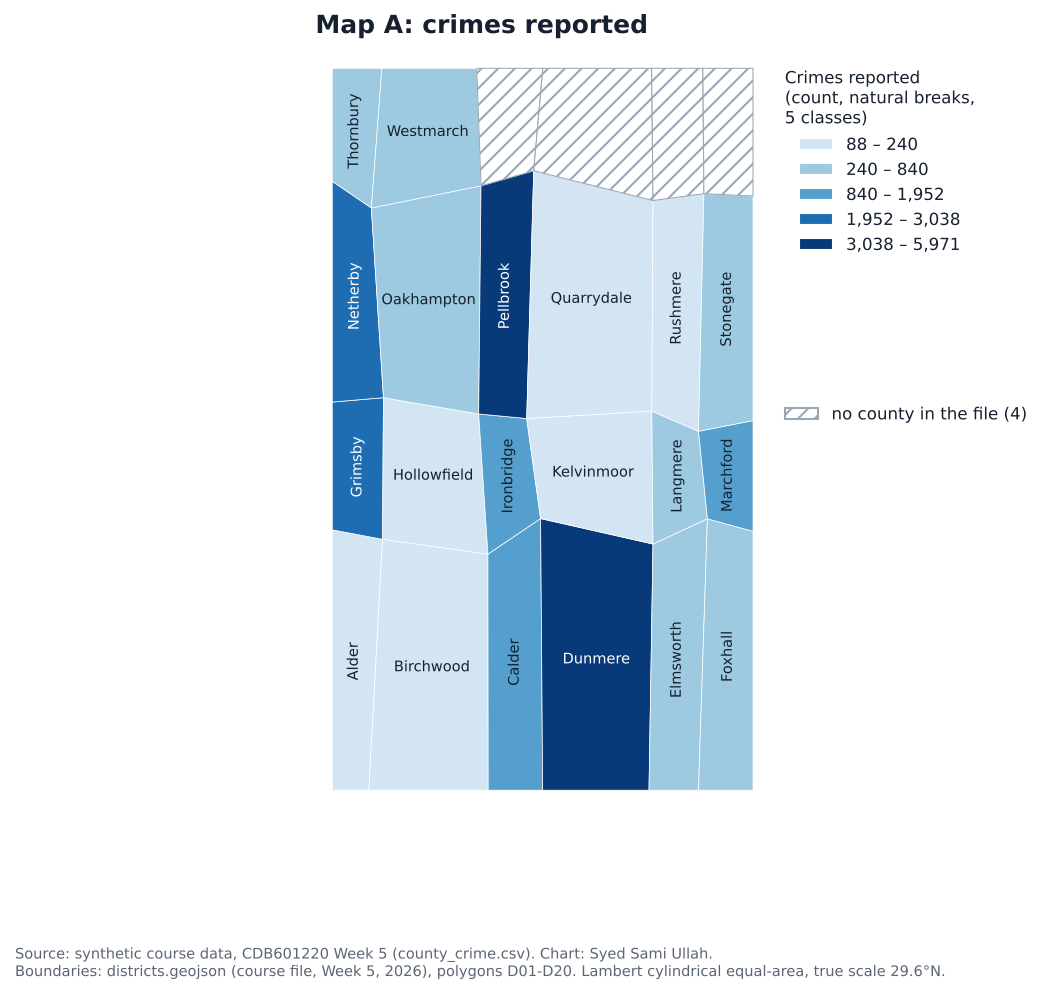

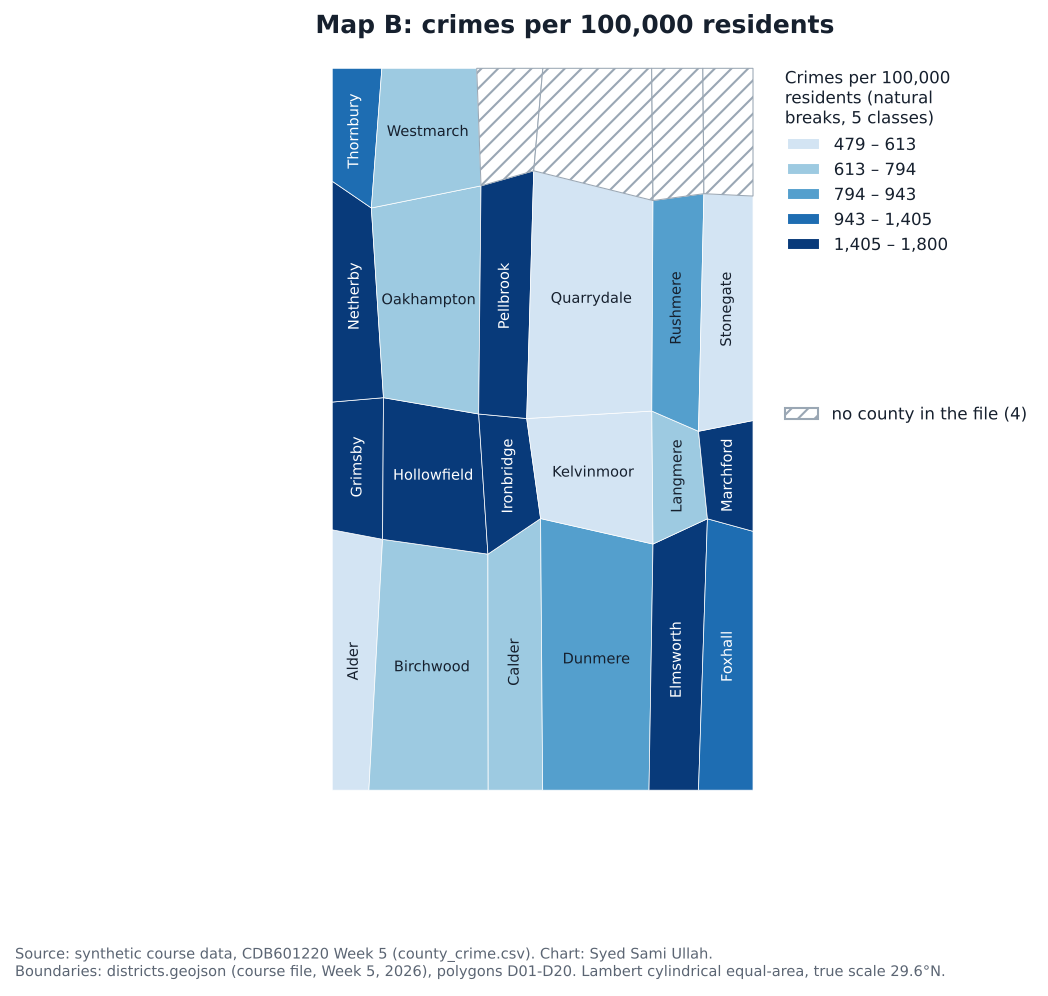

Map A breaks: [88, 240, 840, 1952, 3038, 5971]
Map B breaks: [479, 613, 794, 943, 1405, 1800]


In [3]:
feats20 = [f for f in FEATS if f["code"] in set(cc.code)]
missing = [f for f in FEATS if f["code"] not in set(cc.code)]
names = dict(zip(cc.code, cc.county))


def county_map(ax, column, title, legend_title, fmt):
    edges = gl.choropleth(ax, feats20, dict(zip(cc.code, cc[column])), "natural", 5,
                          legend_title=legend_title, fmt=fmt)
    for f in missing:                                  # same projection reference as the 20 drawn
        x, y = gl.equal_area_xy([p[0] for p in f["ring"]], [p[1] for p in f["ring"]], lat_ts=LAT20)
        ax.add_patch(MplPolygon(np.column_stack([x, y]), closed=True, facecolor="white", edgecolor=GREY,
                                hatch="///", lw=0.5))
    leg = ax.get_legend()
    ax.add_artist(leg)
    ax.legend(handles=[Patch(facecolor="white", edgecolor=GREY, hatch="///", label="no county in the file (4)")],
              loc="upper left", bbox_to_anchor=(1.0, 0.55), fontsize=8, frameon=False)
    ax.autoscale_view()
    cls = dict(zip(cc.code, gl.class_of(cc[column], edges)))
    for f in feats20:
        x, y = gl.equal_area_xy(*gl.representative_point(f["ring"]), lat_ts=LAT20)
        rx, _ = gl.equal_area_xy([p[0] for p in f["ring"]], [p[1] for p in f["ring"]], lat_ts=LAT20)
        narrow = (max(rx) - min(rx)) < 120                      # km; too thin for a horizontal name
        ax.text(x, y, names[f["code"]], ha="center", va="center", fontsize=7, rotation=90 if narrow else 0,
                color="white" if cls[f["code"]] >= 3 else INK, clip_on=False)
    ax.margins(x=0.04, y=0.02)
    ax.set_title(title, fontsize=12)
    return edges


def map_a(ax=None):
    fig, ax = plt.subplots(figsize=(7, 6.5)) if ax is None else (ax.figure, ax)
    e = county_map(ax, "crimes_reported", "Map A: crimes reported", "Crimes reported\n(count, natural breaks,\n5 classes)", "{:,.0f}")
    return fig, e


def map_b(ax=None):
    fig, ax = plt.subplots(figsize=(7, 6.5)) if ax is None else (ax.figure, ax)
    e = county_map(ax, "rate", "Map B: crimes per 100,000 residents",
                   "Crimes per 100,000\nresidents (natural\nbreaks, 5 classes)", "{:,.0f}")
    return fig, e


# the two stimuli shown to readers, one at a time - neutral titles, no hint of the answer
fig, eA = map_a()
save_fig(fig, SUB / "partC_map_A.png", note=NOTE)
show()
fig, eB = map_b()
save_fig(fig, SUB / "partC_map_B.png", note=NOTE)
show()
print("Map A breaks:", [round(float(e)) for e in eA])
print("Map B breaks:", [round(float(e)) for e in eB])

**What these charts show.** Map A: Dunmere (south), Pellbrook (north-centre) and the western strip with Grimsby and Netherby are darkest. Map B: same polygons, but the top class grows to seven counties, including small ones like Hollowfield (12,000 people) and Elmsworth (22,000), and Dunmere drops to the middle class. These two PNGs are the stimuli: each is shown alone, A first.

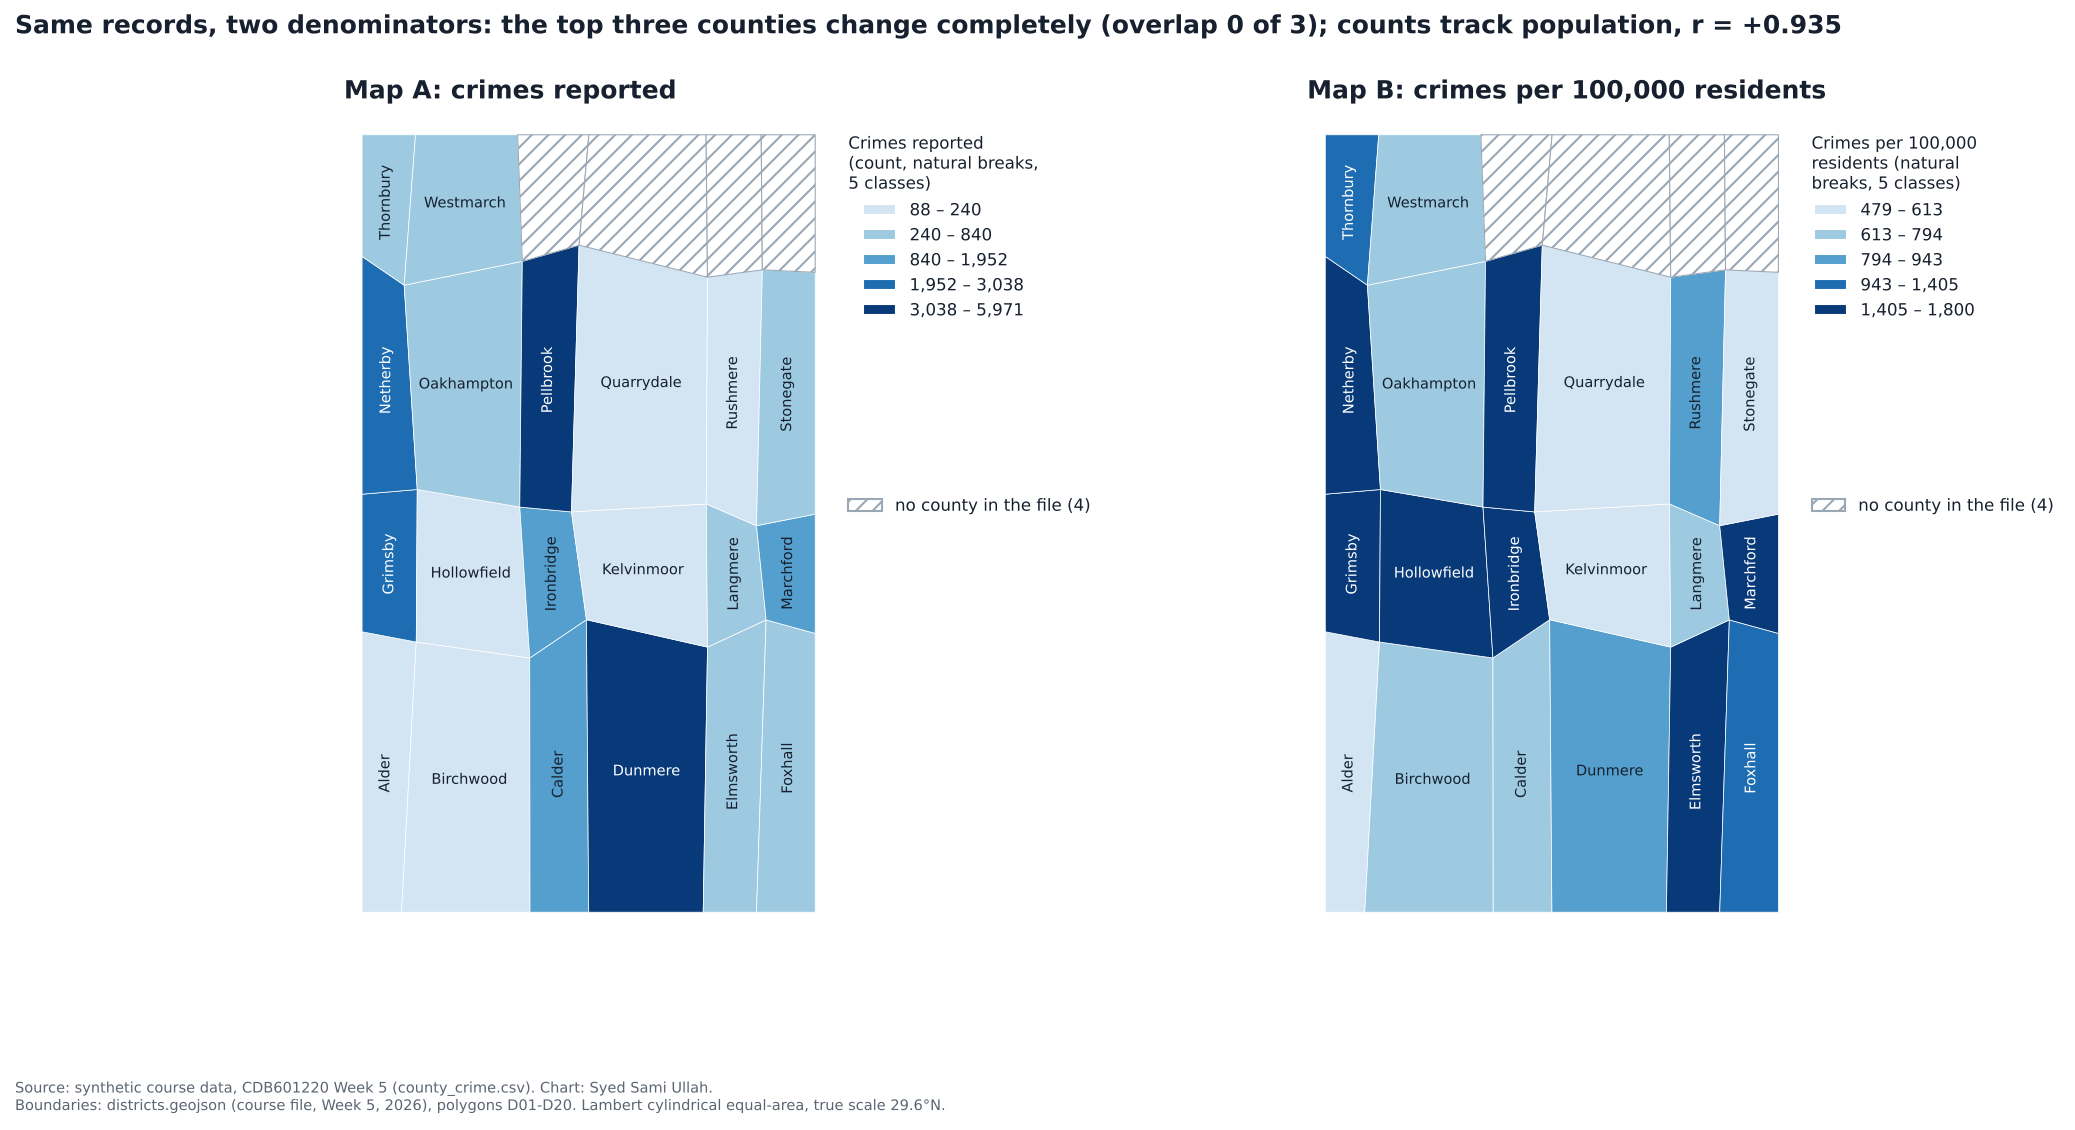

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
map_a(ax1)
map_b(ax2)
fig.subplots_adjust(wspace=0.45)
fig.suptitle(f"Same records, two denominators: the top three counties change completely (overlap 0 of 3); counts track population, r = +{r:.3f}",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
save_fig(fig, CHARTS / "partC_two_maps.png", note=NOTE)
show()

**What this chart shows.** Side by side for the write-up (readers never see this version). The count map follows where people live, the rate map follows risk per resident, and the two league tables share nothing at the top.

## Q2 · The reader harness (4 marks)
Run with at least **five real people**, one at a time, who haven't seen this notebook. The order is fixed: **Map A only** first, ask *"Which three counties would you send extra police to, and why?"*, write their three down. Then **Map B**, same question. They can't go back and change answer 1.

Two ways to record a reader:
- **On screen:** set `RUN_EXPERIMENT = True` and the reader's name and run the cell (or `python submission/partC_maps.py --run "Name"` from a terminal). It shows Map A, takes three names, then shows Map B.
- **On paper / printed maps:** show `partC_map_A.png`, then `partC_map_B.png`, write the answers down, then record them with `python submission/partC_maps.py --record "Name" --a "x, y, z" --b "x, y, z"`.

Either way the row goes into `partC_reader_results.csv` with a timestamp. The "why" answers go in my notes, not the CSV.

In [5]:
RUN_EXPERIMENT = False          # set True only when a real reader is sitting in front of the screen
READER = "reader_1"             # their name or initials
COUNTIES = cc.county.tolist()


def parse_three(text):
    """Match typed names to counties (case-insensitive, a unique prefix is enough)."""
    picks = []
    for part in [t.strip() for t in text.replace(";", ",").split(",") if t.strip()]:
        hits = [c for c in COUNTIES if c.lower().startswith(part.lower())]
        if len(hits) != 1:
            raise ValueError(f"'{part}' doesn't match exactly one county")
        picks.append(hits[0])
    if len(picks) != 3 or len(set(picks)) != 3:
        raise ValueError("need exactly three different counties")
    return picks


def record(reader, a, b, how):
    row = {"reader": reader, **{f"a{i + 1}": v for i, v in enumerate(a)}, **{f"b{i + 1}": v for i, v in enumerate(b)},
           "overlap": len(set(a) & set(b)), "how": how, "recorded_at": datetime.now().isoformat(timespec="seconds")}
    old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=COLUMNS)
    pd.concat([old, pd.DataFrame([row])], ignore_index=True)[COLUMNS].to_csv(RESULTS, index=False)
    print(f"saved {reader}: A {a} | B {b} | overlap {row['overlap']}")


def ask(make_map, label):
    fig, _ = make_map()
    if IN_NOTEBOOK:
        from IPython.display import display, clear_output
        display(fig)
    else:
        plt.show(block=False)
        plt.pause(0.5)
    while True:
        try:
            picks = parse_three(input(f"[{label}] Which three counties would you send extra police to? (comma-separated): "))
            break
        except ValueError as err:
            print(err)
    plt.close(fig)
    if IN_NOTEBOOK:
        clear_output()
    return picks


def run_reader(reader):
    a = ask(map_a, "Map A")
    b = ask(map_b, "Map B")
    record(reader, a, b, "screen")


if not RESULTS.exists():
    pd.DataFrame(columns=COLUMNS).to_csv(RESULTS, index=False)      # empty template, header only
if RUN_EXPERIMENT:
    run_reader(READER)
else:
    print("RUN_EXPERIMENT is False - no reader recorded in this run.")

RUN_EXPERIMENT is False - no reader recorded in this run.


## Q3 · Report it (2 marks)

In [6]:
res = pd.read_csv(RESULTS)
if len(res):
    res["a_is_count_top3"] = res[["a1", "a2", "a3"]].apply(lambda r_: len(set(r_) & set(top_count)), axis=1)
    res["b_is_rate_top3"] = res[["b1", "b2", "b3"]].apply(lambda r_: len(set(r_) & set(top_rate)), axis=1)
    print(res[["reader", "a1", "a2", "a3", "b1", "b2", "b3", "overlap", "a_is_count_top3", "b_is_rate_top3", "how"]].to_string(index=False))
    print(f"\nreaders: {len(res)}  |  mean overlap between their A and B picks: {res.overlap.mean():.2f} of 3")
    print("overlap counts:", res.overlap.value_counts().sort_index().to_dict())
    print(f"mean picks that were the count top 3 on A: {res.a_is_count_top3.mean():.2f}; the rate top 3 on B: {res.b_is_rate_top3.mean():.2f}")
    if len(res) < 5:
        print(f"\nonly {len(res)} reader(s) so far - the brief needs at least 5")
else:
    print("No reader has been run yet - partC_reader_results.csv only has its header, so there is nothing to report.")
    print("Run the harness above with at least five real people, then re-run this cell.")

No reader has been run yet - partC_reader_results.csv only has its header, so there is nothing to report.
Run the harness above with at least five real people, then re-run this cell.


**What each map is a map of.** Map A is a map of **where people live**: crimes track population at r = +0.935, so the dark counties are just the big ones. Map B is a map of **risk per resident**, and its top three (Hollowfield, Netherby, Elmsworth) share none of Map A's. Hollowfield (12,000 people) and Elmsworth (22,000) jump from the bottom of the count map to the top of the rate map. Those two are also small enough that a handful of incidents moves them a lot (case 6's lesson), so I'd want a funnel check before sending police there on Map B alone.

**The result.** The mean overlap goes here once at least five real readers have done it. The cell above prints it straight from the CSV. If readers pick the same three from both maps, that's a result too, and I'll report it as it came out.

In [7]:
if __name__ == "__main__" and not IN_NOTEBOOK:
    ap = argparse.ArgumentParser()
    ap.add_argument("--run", metavar="READER", help="show the maps on screen to one real reader and record their picks")
    ap.add_argument("--record", metavar="READER", help="record a reader whose answers were taken on paper")
    ap.add_argument("--a", help='their three from Map A, e.g. "Dunmere, Pellbrook, Grimsby"')
    ap.add_argument("--b", help="their three from Map B")
    args, _ = ap.parse_known_args()
    if args.run:
        run_reader(args.run)
    elif args.record:
        record(args.record, parse_three(args.a), parse_three(args.b), "paper")